In [1]:
%pip install -U pandas numpy matplotlib seaborn scikit-learn flask


   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/10.9 MB 16.5 MB/s eta 0:00:01
   ----------------------- ---------------- 6.3/10.9 MB 15.5 MB/s eta 0:00:01
   ---------------------------------- ----- 9.4/10.9 MB 15.7 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 14.9 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ----------- ---------------------------- 3.7/12.7 MB 19.0 MB/s eta 0:00:01
   -------------------------- ------------- 8.4/12.7 MB 20.2 MB/s eta 0:00:01
   ---------------------------------------  12.6/12.7 MB 20.2 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 18.9 MB/s  0:00:00
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----------------- ---------------------- 4.2/9.5 MB 19.4 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.5 MB 19.0 MB/s eta 0:00:01
   -------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.65.1 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


In [4]:
pip install --upgrade numba

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------------------------- -------------- 1.8/2.8 MB 13.6 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 14.2 MB/s  0:00:00
   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---- ----------------------------------- 4.5/43.0 MB 22.1 MB/s eta 0:00:02
   -------- ------------------------------- 8.7/43.0 MB 20.8 MB/s eta 0:00:02
   ------------ --------------------------- 13.4/43.0 MB 21.0 MB/s eta 0:00:02
   ---------------- ----------------------- 17.3/43.0 MB 20.4 MB/s eta 0:00:02
   -------------------- ------------------- 21.8/43.0 MB 20.4 MB/s eta 0:00:02
   ------------------------ --------------- 26.7/43.0 MB 20.9 MB/s eta 0:00:01
   ---------------------------- ----------- 30.9/43.0 MB 20.7 MB/s eta 0:00:01
   --------------------------------- ------ 35.7/43.0 MB 20.9 MB/s eta 0:00:01
   ------------------------------------- -- 40.6/43.0 MB 21.1 MB/s eta 0:00:01
 

## 1. Importaciones y rutas


In [1]:
from pathlib import Path
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "dataset_estudiantes_balanceado.csv"
MODEL_DIR = BASE_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)





## 2. Cargar y explorar los datos
El taller describe 600 registros. Esta celda muestra el tamaño real y los valores nulos para confirmar el archivo.

In [4]:
df = pd.read_csv(DATA_PATH)
print("Dimensiones del dataset:", df.shape)
display(df.head())
display(df.isnull().sum().to_frame("valores_nulos"))
print("\nColumnas:", df.columns.tolist())


Dimensiones del dataset: (600, 8)


,Tareas,Examenes,Asistencia,Estudio_Horas,Sueno_Horas,Extracurriculares,Calificacion_Final,Aprobado
0,56.217808,33.514805,85.495792,23.999532,5.703021,1,79.671652,1
1,96.550001,42.287227,41.475215,18.962692,4.358559,1,82.650731,1
2,81.239576,34.160839,41.327413,10.124782,6.048144,0,60.380195,0
3,71.906094,27.096203,59.416613,13.791209,5.556087,1,63.816827,0
4,40.921305,29.650870,69.806012,10.043174,7.385603,0,49.874904,0


,valores_nulos
Tareas,0
Examenes,0
Asistencia,0
Estudio_Horas,0
Sueno_Horas,0
Extracurriculares,0
Calificacion_Final,0
Aprobado,0



Columnas: ['Tareas', 'Examenes', 'Asistencia', 'Estudio_Horas', 'Sueno_Horas', 'Extracurriculares', 'Calificacion_Final', 'Aprobado']


## 3. Comprobar las clases y preparar las variables


In [6]:
TARGET = "Aprobado"
FEATURES = [
    "Tareas", "Examenes", "Asistencia",
    "Estudio_Horas", "Sueno_Horas", "Extracurriculares"
]

required = FEATURES + [TARGET]
missing_columns = [col for col in required if col not in df.columns]
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas en el CSV: {missing_columns}")

.
df_model = df.dropna(subset=[TARGET]).copy()

# Verificar que la etiqueta sea binaria y convertible a 0/1.
target_values = set(pd.to_numeric(df_model[TARGET], errors="coerce").dropna().unique())
if not target_values.issubset({0, 1}) or len(target_values) != 2:
    raise ValueError(f"La columna {TARGET} debe contener las dos clases 0 y 1. Valores detectados: {target_values}")

y = pd.to_numeric(df_model[TARGET]).astype(int)
X = df_model[FEATURES].copy()

class_counts = y.value_counts().sort_index()
class_percent = (y.value_counts(normalize=True).sort_index() * 100).round(2)
display(pd.DataFrame({"cantidad": class_counts, "porcentaje": class_percent}))


print("Filas utilizables:", len(X))
print("Características:", FEATURES)

,cantidad,porcentaje
Aprobado,,
0,300,50.0
1,300,50.0


Filas utilizables: 600
Características: ['Tareas', 'Examenes', 'Asistencia', 'Estudio_Horas', 'Sueno_Horas', 'Extracurriculares']


## 4. Separar entrenamiento y prueba
Se divide primero. El imputador y el escalador se ajustan después únicamente con el conjunto de entrenamiento, evitando fuga de información.

In [9]:
pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        batch_size=32,
        learning_rate="adaptive",
        max_iter=500,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        verbose=True
    ))
])

pipeline.fit(X_train, y_train)
print("Entrenamiento terminado.")
print("Iteraciones realizadas:", pipeline.named_steps["mlp"].n_iter_)

Iteration 1, loss = 0.63077999
Validation score: 0.791667
Iteration 2, loss = 0.50993328
Validation score: 0.854167
Iteration 3, loss = 0.40908465
Validation score: 0.854167
Iteration 4, loss = 0.32730973
Validation score: 0.854167
Iteration 5, loss = 0.26367898
Validation score: 0.875000
Iteration 6, loss = 0.21879863
Validation score: 0.895833
Iteration 7, loss = 0.18711769
Validation score: 0.937500
Iteration 8, loss = 0.16070287
Validation score: 0.958333
Iteration 9, loss = 0.14120776
Validation score: 0.958333
Iteration 10, loss = 0.12618740
Validation score: 0.958333
Iteration 11, loss = 0.11315204
Validation score: 1.000000
Iteration 12, loss = 0.10239531
Validation score: 1.000000
Iteration 13, loss = 0.09430857
Validation score: 0.979167
Iteration 14, loss = 0.08613999
Validation score: 1.000000
Iteration 15, loss = 0.07949002
Validation score: 1.000000
Iteration 16, loss = 0.07364886
Validation score: 1.000000
Iteration 17, loss = 0.06877193
Validation score: 1.000000
Iterat

## 5. Construir y entrenar el MLP
La tubería aplica mediana a las características, estandarización y finalmente el clasificador MLP.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)
print("Distribución en entrenamiento:")
display(y_train.value_counts(normalize=True).sort_index().mul(100).round(2).to_frame("porcentaje"))
print("Distribución en prueba:")
display(y_test.value_counts(normalize=True).sort_index().mul(100).round(2).to_frame("porcentaje"))

Entrenamiento: (480, 6) Prueba: (120, 6)
Distribución en entrenamiento:


,porcentaje
Aprobado,
0,50.0
1,50.0


Distribución en prueba:


,porcentaje
Aprobado,
0,50.0
1,50.0


## 6. Evaluar el conjunto de prueba
Estas métricas se calculan sobre datos que no participaron en el ajuste del pipeline.

In [10]:
y_pred = pipeline.predict(X_test)

metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1": float(f1_score(y_test, y_pred, zero_division=0))
}

print("=== MÉTRICAS EN TEST ===")
for name, value in metrics.items():
    print(f"{name.capitalize()}: {value:.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["Reprobado", "Aprobado"],
    zero_division=0
))

=== MÉTRICAS EN TEST ===
Accuracy: 0.9667
Precision: 0.9516
Recall: 0.9833
F1: 0.9672

Reporte de clasificación:
              precision    recall  f1-score   support

   Reprobado       0.98      0.95      0.97        60
    Aprobado       0.95      0.98      0.97        60

    accuracy                           0.97       120
   macro avg       0.97      0.97      0.97       120
weighted avg       0.97      0.97      0.97       120



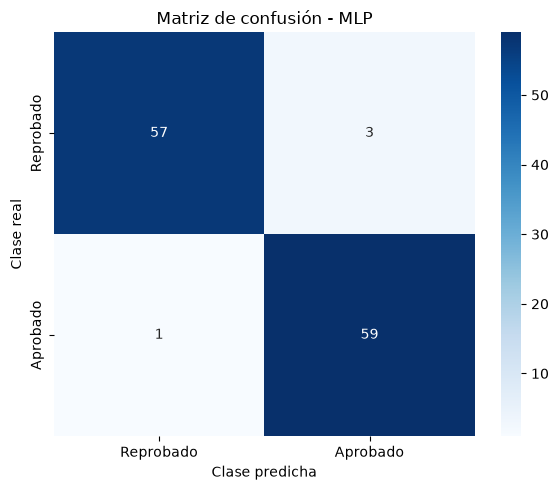

Matriz guardada en: C:\Users\USUARIO\Downloads\Laboratorio_MLP_\model\confusion_matrix.png


In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Reprobado", "Aprobado"],
    yticklabels=["Reprobado", "Aprobado"]
)
plt.title("Matriz de confusión - MLP")
plt.ylabel("Clase real")
plt.xlabel("Clase predicha")
plt.tight_layout()

cm_path = MODEL_DIR / "confusion_matrix.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print("Matriz guardada en:", cm_path)

## 7. Guardar los artefactos


In [12]:
model_path = MODEL_DIR / "mlp_pipeline.pkl"
with open(model_path, "wb") as f:
    pickle.dump(pipeline, f)

with open(MODEL_DIR / "features.json", "w", encoding="utf-8") as f:
    json.dump(FEATURES, f, ensure_ascii=False, indent=2)

with open(MODEL_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("Artefactos guardados:")
for path in sorted(MODEL_DIR.iterdir()):
    print("-", path.name)

Artefactos guardados:
- confusion_matrix.png
- features.json
- metrics.json
- mlp_pipeline.pkl


In [16]:
import sklearn
import numpy
import pandas
import flask

print("scikit-learn:", sklearn.__version__)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("flask:", flask.__version__)

scikit-learn: 1.9.1
numpy: 2.5.4
pandas: 3.1.0
flask: 3.1.3


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_29436\1819955495.py:9: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("flask:", flask.__version__)
